1. Cargando y procesando datos clínicos...
   -> Pacientes clínicos listos: 209
2. Cargando predicciones y filogenia...
3. Calculando métricas de carga inmunogénica y filogenia...
4. Cruzando con clínica y ajustando Modelo Cox...
   -> Pacientes finales para el modelo Cox: 118

--- RESUMEN DEL MODELO COX MULTIVARIANTE ---


<lifelines.CoxPHFitter: fitted with 118 total observations, 12 right-censored observations>
             duration col = 'Tiempo'
                event col = 'Supervivencia'
                penalizer = 0.01
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 118
number of events observed = 106
   partial log-likelihood = -420.57
         time fit was run = 2026-04-21 13:38:03 UTC

---
                       coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                              
Clonal_Immuno_Load    -0.32      0.73      0.33           -0.97            0.33                0.38                1.40
Subclonal_Immuno_Load  0.16      1.17      0.08           -0.01            0.32                0.99                1.38
CCF_Weighted_Score     0.29      1.34      0.33           -0.36            0.95                0.70                2.58

                       cmp to     z    p  -log2(p)
covariate                                         
Clonal_Immuno_Load       0.00 -0.96 0.34      1.57
Subclonal_Immuno_Load    0.00  1.83 0.07      3.91
CCF_Weighted_Score       0.00  0.89 0.38      1.41
---
Concordance = 0.54
Partial AIC = 847.13
log-likelihood ratio test = 3.74 on 3 df
-log2(p) of ll-ratio test = 1.78

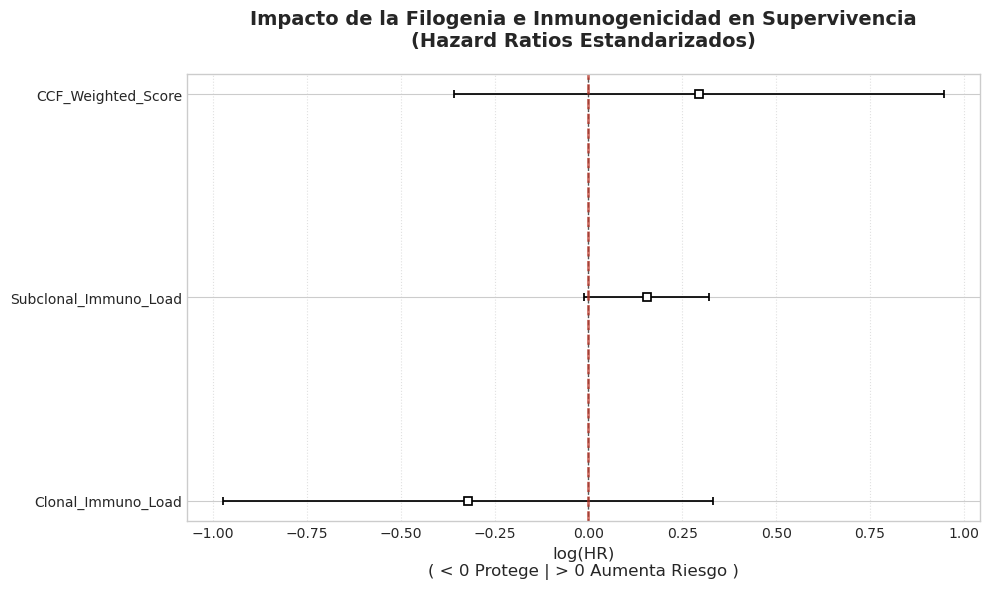

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter

# Configuración estética
plt.style.use('seaborn-v0_8-whitegrid')

# ==============================================================================
# 1. CARGAR Y PREPARAR DATOS CLÍNICOS (CON RESCATE DE FOLLOW-UP)
# ==============================================================================
print("1. Cargando y procesando datos clínicos...")
df_au = pd.read_csv('../data/raw/clinical_data_APGI/donor.tsv', sep='\t')
df_ca = pd.read_csv('../data/raw/clinical_data_PACA/donor.tsv', sep='\t')
df_clinico = pd.concat([df_au, df_ca], ignore_index=True)

df_clinico['ID_Paciente'] = 'DO' + df_clinico['donor_id'].astype(str)
df_clinico['Tiempo'] = pd.to_numeric(df_clinico['survival_time'], errors='coerce')
df_clinico['Supervivencia'] = np.where(df_clinico['vital_status'] == 'Deceased', 1, 0)
df_clinico.loc[df_clinico['vital_status'].isna(), 'Supervivencia'] = np.nan

# Rescate de Follow-up
df_follow_au = pd.read_csv('../data/raw/clinical_data_APGI/follow_up.tsv', sep='\t')
df_follow_ca = pd.read_csv('../data/raw/clinical_data_PACA/follow_up.tsv', sep='\t')
df_follow = pd.concat([df_follow_au, df_follow_ca], ignore_index=True)

df_follow['interval_of_followup'] = pd.to_numeric(df_follow['interval_of_followup'], errors='coerce')
ultimos_seguimientos = df_follow.groupby('donor_id')['interval_of_followup'].max().reset_index()
ultimos_seguimientos['ID_Paciente'] = 'DO' + ultimos_seguimientos['donor_id'].astype(str)
ultimos_seguimientos.rename(columns={'interval_of_followup': 'Tiempo_FollowUp'}, inplace=True)

df_clinico = pd.merge(df_clinico, ultimos_seguimientos[['ID_Paciente', 'Tiempo_FollowUp']], on='ID_Paciente', how='left')
df_clinico['Tiempo'] = df_clinico['Tiempo'].fillna(df_clinico['Tiempo_FollowUp'])
df_clinico = df_clinico.dropna(subset=['Tiempo', 'Supervivencia'])
print(f"   -> Pacientes clínicos listos: {len(df_clinico)}")


# ==============================================================================
# 2. CARGAR DATOS DE NEOANTÍGENOS Y FILOGENIA
# ==============================================================================
print("2. Cargando predicciones y filogenia...")
# Ajusta estas rutas a donde tengas realmente estos dos CSVs
ruta_preds = "../data/processed/Full_Dataset_Predictions.csv" 
ruta_filo = "../data/raw/Master_Neoantigenos_Filogenia_PhyClone.csv" # Pon la ruta completa si no está en la carpeta actual

df_preds = pd.read_csv(ruta_preds, low_memory=False)
df_final = pd.read_csv(ruta_filo, low_memory=False)

# Normalizar nombre de columna si es necesario
df_preds = df_preds.rename(columns={'Peptide': 'mut_seq'}) if 'Peptide' in df_preds.columns else df_preds

# ==============================================================================
# 3. INTEGRAR Y CALCULAR MÉTRICAS FILOGENÉTICAS
# ==============================================================================
print("3. Calculando métricas de carga inmunogénica y filogenia...")
df_plot = pd.merge(
    df_preds[['patient', 'mut_seq', 'gene', 'Immunogenicity_Probability']], # <-- Añade 'gene' aquí
    df_final[['patient', 'mut_seq', 'CCF', 'clonality']].drop_duplicates(subset=['patient','mut_seq']),
    on=['patient', 'mut_seq'],
    how='inner'
)
df_plot['clonality'] = df_plot['clonality'].astype(str).str.capitalize().str.strip()

# Parámetro clave basado en tus gráficas anteriores
umbral_inmuno = 0.5 

# Subconjunto de alta inmunogenicidad
df_high_immuno = df_plot[df_plot['Immunogenicity_Probability'] >= umbral_inmuno]

# Métrica A: Carga Clonal Inmunogénica
clonal_load = df_high_immuno[df_high_immuno['clonality'] == 'Clonal'].groupby('patient').size().reset_index(name='Clonal_Immuno_Load')

# Métrica B: Carga Subclonal Inmunogénica
subclonal_load = df_high_immuno[df_high_immuno['clonality'] == 'Subclonal'].groupby('patient').size().reset_index(name='Subclonal_Immuno_Load')

# Métrica C: Score Ponderado por CCF (Usa todos los péptidos, sin importar el umbral)
df_plot['Weighted_Value'] = df_plot['Immunogenicity_Probability'] * df_plot['CCF']
ccf_weighted = df_plot.groupby('patient')['Weighted_Value'].sum().reset_index(name='CCF_Weighted_Score')

# Unificar todo por paciente
df_metrics = pd.DataFrame({'patient': df_plot['patient'].unique()})
df_metrics = pd.merge(df_metrics, clonal_load, on='patient', how='left')
df_metrics = pd.merge(df_metrics, subclonal_load, on='patient', how='left')
df_metrics = pd.merge(df_metrics, ccf_weighted, on='patient', how='left')

# Rellenar con 0 a los pacientes que no pasaron los filtros
df_metrics = df_metrics.fillna(0)
df_metrics.rename(columns={'patient': 'ID_Paciente'}, inplace=True)


# ==============================================================================
# 4. PREPARAR EL MODELO DE COX Y ESTANDARIZAR
# ==============================================================================
print("4. Cruzando con clínica y ajustando Modelo Cox...")
df_cox = pd.merge(df_clinico[['ID_Paciente', 'Tiempo', 'Supervivencia']], df_metrics, on='ID_Paciente', how='inner')
print(f"   -> Pacientes finales para el modelo Cox: {len(df_cox)}")

# Estandarizamos (Z-score) para que los coeficientes sean comparables y el modelo converja bien
cols_to_scale = ['Clonal_Immuno_Load', 'Subclonal_Immuno_Load', 'CCF_Weighted_Score']
for col in cols_to_scale:
    df_cox[col] = (df_cox[col] - df_cox[col].mean()) / df_cox[col].std()

# Preparamos el dataframe final para lifelines (solo variables numéricas)
df_cox_fit = df_cox.drop(columns=['ID_Paciente'])


# ==============================================================================
# 5. EJECUTAR Y VISUALIZAR
# ==============================================================================
cph_multi = CoxPHFitter(penalizer=0.01) # Ligera penalización L2 por si hay colinealidad fuerte
cph_multi.fit(df_cox_fit, duration_col='Tiempo', event_col='Supervivencia')

print("\n--- RESUMEN DEL MODELO COX MULTIVARIANTE ---")
cph_multi.print_summary()

# Gráfica del Forest Plot
plt.figure(figsize=(10, 6))
cph_multi.plot()
plt.title("Impacto de la Filogenia e Inmunogenicidad en Supervivencia\n(Hazard Ratios Estandarizados)", 
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel("log(HR)\n( < 0 Protege | > 0 Aumenta Riesgo )", fontsize=12)
plt.axvline(0, color='#c0392b', linestyle='--', alpha=0.7, linewidth=2)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

/tmp/ipykernel_2941/2793519368.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


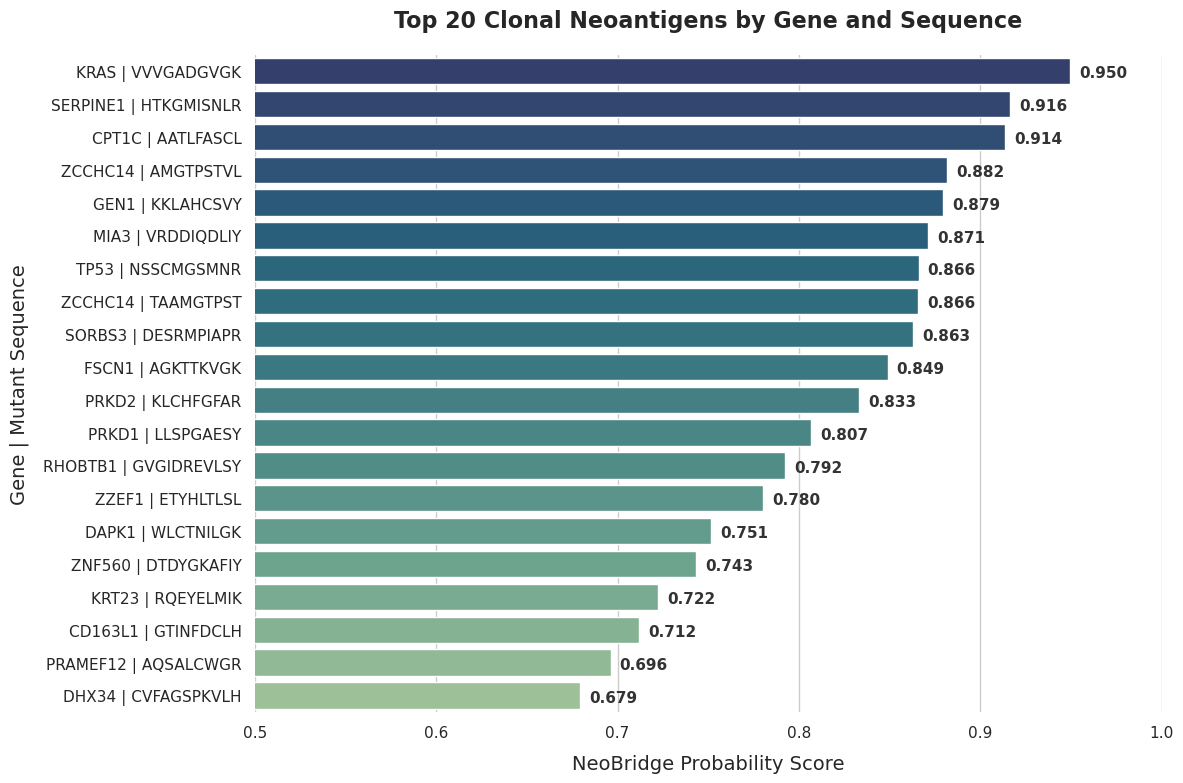

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# ==============================================================================
# FUNCIÓN PARA ELIMINAR PÉPTIDOS REDUNDANTES (ANIDADOS)
# ==============================================================================
def filter_nested_peptides(df):
    """
    Filtra péptidos del mismo gen/paciente que son subcadenas unos de otros.
    Mantiene siempre el que tiene mayor probabilidad.
    """
    # Ordenamos de mayor a menor probabilidad para procesar siempre el mejor primero
    df_sorted = df.sort_values(by='Immunogenicity_Probability', ascending=False)
    
    kept_indices = []
    accepted_seqs = {} # Diccionario para guardar las secuencias ya aceptadas por gen
    
    for idx, row in df_sorted.iterrows():
        key = (row['patient'], row['gene'])
        seq = row['mut_seq']
        
        if key not in accepted_seqs:
            accepted_seqs[key] = []
            
        # Comprobar si la secuencia actual está contenida en alguna ya aceptada, 
        # o si alguna aceptada está contenida en la actual (redundancia)
        is_redundant = False
        for acc_seq in accepted_seqs[key]:
            if seq in acc_seq or acc_seq in seq:
                is_redundant = True
                break
                
        # Si no es redundante, la guardamos
        if not is_redundant:
            accepted_seqs[key].append(seq)
            kept_indices.append(idx)
            
    return df_sorted.loc[kept_indices]

# ==============================================================================
# PROCESAMIENTO Y GRÁFICO
# ==============================================================================

# 1. Filtrar candidatos clonales
df_clonales = df_plot[df_plot['clonality'] == 'Clonal'].copy()

# 2. Aplicar el filtro de péptidos redundantes
df_clonales_limpio = filter_nested_peptides(df_clonales)

# 3. Extraer el Top 20 real (ya sin redundancias)
top_20_clonales = df_clonales_limpio.head(20).copy()

# 4. Crear la etiqueta del eje Y (GEN | Secuencia)
top_20_clonales['Y_Label'] = top_20_clonales['gene'].astype(str) + " | " + top_20_clonales['mut_seq']

# 5. Configuración de la figura
plt.figure(figsize=(12, 8))
sns.set_theme(style="whitegrid")

# Usamos 'mako' (tonos azules/esmeralda oscuros muy profesionales) 
# Alternativas elegantes: 'viridis', 'Blues_r', 'crest'
ax = sns.barplot(
    x='Immunogenicity_Probability', 
    y='Y_Label', 
    data=top_20_clonales,
    palette='crest_r' 
)

# 6. Personalización de títulos y ejes
plt.title("Top 20 Clonal Neoantigens by Gene and Sequence", fontsize=16, fontweight='bold', pad=20)
plt.xlabel("NeoBridge Probability Score", fontsize=14, labelpad=10)
plt.ylabel("Gene | Mutant Sequence", fontsize=14, labelpad=10)

# El límite en 0.5 resalta las diferencias en la zona de alta probabilidad
plt.xlim(0.5, 1.0) 

# 7. Añadir etiquetas de valor numérico
for p in ax.patches:
    width = p.get_width()
    plt.text(width + 0.005, p.get_y() + p.get_height()/2. + 0.05, 
             f'{width:.3f}', ha='left', va='center', fontsize=11, fontweight='bold', color='#333333')

sns.despine(left=True, bottom=True)
plt.tight_layout()
# --- CAMBIO AQUÍ ---
# 8. Asegurar que el directorio existe y guardar ANTES de mostrar
output_dir = '../results/figures/phylogeny_survival/'
os.makedirs(output_dir, exist_ok=True) # Crea la carpeta si no existe
plt.savefig(os.path.join(output_dir, 'Top20_Clonales_Filtered_mako.png'), dpi=300, bbox_inches='tight')

# 9. Mostrar la figura al final
plt.show()

1. Calculando Supervivencia Libre de Progresión (PFS)...
   -> Pacientes con datos de PFS listos: 209
2. Extrayendo covariables clínicas...
3. Cargando predicciones y filogenia...
4. Calculando métricas de carga inmunogénica...
5. Cruzando matrices y ajustando Modelo Cox...

--- RESUMEN DEL MODELO COX MULTIVARIANTE (PFS + CLÍNICA) ---


<lifelines.CoxPHFitter: fitted with 118 total observations, 27 right-censored observations>
             duration col = 'PFS_Time'
                event col = 'PFS_Event'
                penalizer = 0.01
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 118
number of events observed = 91
   partial log-likelihood = -353.61
         time fit was run = 2026-04-21 13:38:27 UTC

---
                       coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                              
Clonal_Immuno_Load    -0.47      0.63      0.34           -1.14            0.20                0.32                1.23
Subclonal_Immuno_Load  0.30      1.35      0.09            0.12            0.47                1.13                1.60
CCF_Weighted_Score     0.40      1.49      0.34           -0.27            1.07                0.76                2.93
bmi                    0.03      1.03      0.10           -0.17            0.23                0.84                1.26
age_at_diagnosis      -0.36      0.70      0.12           -0.60           -0.12                0.55                0.89
gender_Female         -0.39      0.68      0.22           -0.83            0.05                0.44                1.05
Stage_Advanced        -1.02      0.36      1.02           -3.02            0.98                0.05                2.67

                       cmp to     z      p  -log2(p)
covariate                                           
Clonal_Immuno_Load       0.00 -1.37   0.17      2.54
Subclonal_Immuno_Load    0.00  3.36 <0.005     10.32
CCF_Weighted_Score       0.00  1.17   0.24      2.05
bmi                      0.00  0.28   0.78      0.36
age_at_diagnosis         0.00 -2.94 <0.005      8.27
gender_Female            0.00 -1.74   0.08      3.63
Stage_Advanced           0.00 -1.00   0.32      1.65
---
Concordance = 0.63
Partial AIC = 721.22
log-likelihood ratio test = 18.19 on 7 df
-log2(p) of ll-ratio test = 6.49

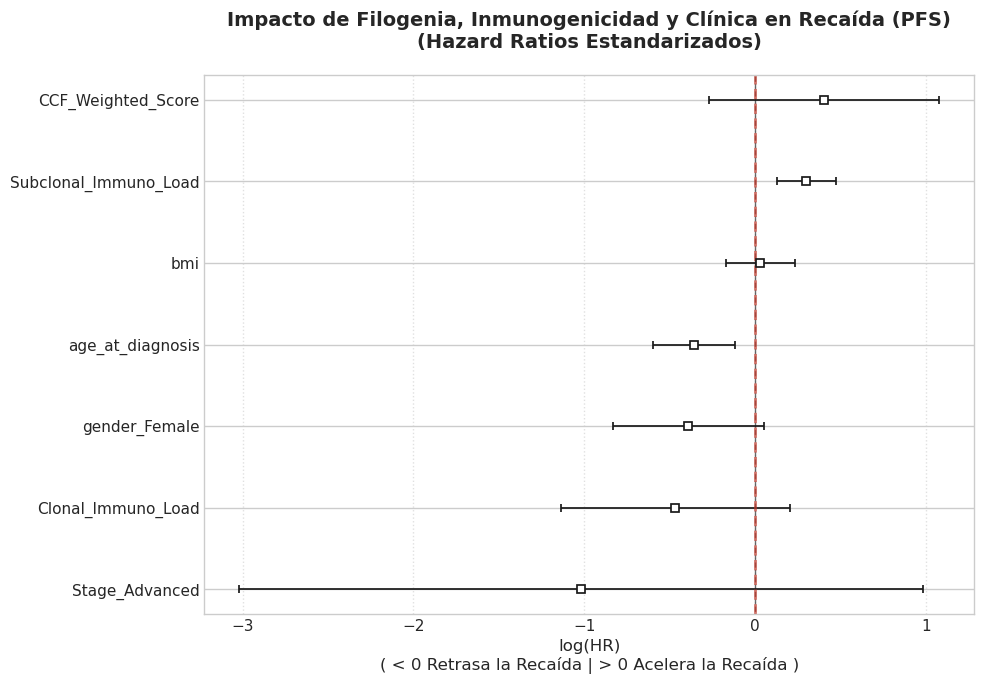

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter

# Configuración estética
plt.style.use('seaborn-v0_8-whitegrid')

# Definir las rutas base
path_apgi = '../data/raw/clinical_data_APGI/'
path_paca = '../data/raw/clinical_data_PACA/'

# ==============================================================================
# 1. CARGAR Y PREPARAR SUPERVIVENCIA LIBRE DE PROGRESIÓN (PFS)
# ==============================================================================
print("1. Calculando Supervivencia Libre de Progresión (PFS)...")

df_fu_apgi = pd.read_csv(path_apgi + 'follow_up.tsv', sep='\t')
df_fu_paca = pd.read_csv(path_paca + 'follow_up.tsv', sep='\t')
df_fu = pd.concat([df_fu_apgi, df_fu_paca], ignore_index=True)

# Asegurar variables numéricas
df_fu['interval_of_followup'] = pd.to_numeric(df_fu['interval_of_followup'], errors='coerce')
df_fu['relapse_interval'] = pd.to_numeric(df_fu['relapse_interval'], errors='coerce')
df_fu['disease_status_at_followup'] = df_fu['disease_status_at_followup'].astype(str).str.lower()

# Definir el EVENTO (1 = Recaída/Progresión, 0 = Censurado/Estable)
# Buscamos palabras clave en el estado de la enfermedad
df_fu['PFS_Event'] = df_fu['disease_status_at_followup'].apply(
    lambda x: 1 if any(word in x for word in ['progression', 'relapse', 'recurrence']) else 0
)

# Definir el TIEMPO: si hay recaída usamos relapse_interval, si no, el máximo seguimiento
df_fu['PFS_Time'] = np.where(
    df_fu['PFS_Event'] == 1, 
    df_fu['relapse_interval'].fillna(df_fu['interval_of_followup']), 
    df_fu['interval_of_followup']
)

# Ordenar de mayor a menor tiempo y quedarnos con el último reporte de cada paciente
df_pfs = df_fu.sort_values('PFS_Time', ascending=False).drop_duplicates(subset=['donor_id'])
df_pfs['ID_Paciente'] = 'DO' + df_pfs['donor_id'].astype(str)
df_pfs = df_pfs.dropna(subset=['PFS_Time', 'PFS_Event'])
print(f"   -> Pacientes con datos de PFS listos: {len(df_pfs)}")


# ==============================================================================
# 2. EXTRAER COVARIABLES CLÍNICAS (EDAD, SEXO, ESTADIO, BMI)
# ==============================================================================
print("2. Extrayendo covariables clínicas...")

# A. BMI (desde donor.tsv)
df_donor = pd.concat([pd.read_csv(path_apgi + 'donor.tsv', sep='\t'), pd.read_csv(path_paca + 'donor.tsv', sep='\t')], ignore_index=True)
df_bmi = df_donor[['donor_id', 'bmi']].drop_duplicates(subset=['donor_id'])
df_bmi['bmi'] = pd.to_numeric(df_bmi['bmi'], errors='coerce')

# B. EDAD (desde primary_diagnosis.tsv)
df_diag = pd.concat([pd.read_csv(path_apgi + 'primary_diagnosis.tsv', sep='\t'), pd.read_csv(path_paca + 'primary_diagnosis.tsv', sep='\t')], ignore_index=True)
df_age = df_diag[['donor_id', 'age_at_diagnosis']].drop_duplicates(subset=['donor_id'])
df_age['age_at_diagnosis'] = pd.to_numeric(df_age['age_at_diagnosis'], errors='coerce')

# C. SEXO (desde sample_registration.tsv)
df_samp = pd.concat([pd.read_csv(path_apgi + 'sample_registration.tsv', sep='\t'), pd.read_csv(path_paca + 'sample_registration.tsv', sep='\t')], ignore_index=True)
df_sex = df_samp[['donor_id', 'gender']].drop_duplicates(subset=['donor_id'])
df_sex['gender_Female'] = np.where(df_sex['gender'].astype(str).str.lower() == 'female', 1, 0)
df_sex = df_sex.drop(columns=['gender'])

# D. ESTADIO (desde specimen.tsv)
df_spec = pd.concat([pd.read_csv(path_apgi + 'specimen.tsv', sep='\t'), pd.read_csv(path_paca + 'specimen.tsv', sep='\t')], ignore_index=True)
df_stage = df_spec[['donor_id', 'pathological_stage_group']].dropna().drop_duplicates(subset=['donor_id'])

def clean_stage(stage):
    stage = str(stage).upper()
    if 'IV' in stage or 'III' in stage: return 1 # Avanzado
    if 'I' in stage or 'II' in stage: return 0   # Temprano
    return np.nan

df_stage['Stage_Advanced'] = df_stage['pathological_stage_group'].apply(clean_stage)
df_stage = df_stage.drop(columns=['pathological_stage_group'])

# Fusionar todas las covariables
df_cov = df_bmi.merge(df_age, on='donor_id', how='outer').merge(df_sex, on='donor_id', how='outer').merge(df_stage, on='donor_id', how='left')

# Imputación de nulos (Mediana para numéricos, Moda para categóricos)
df_cov['bmi'] = df_cov['bmi'].fillna(df_cov['bmi'].median())
df_cov['age_at_diagnosis'] = df_cov['age_at_diagnosis'].fillna(df_cov['age_at_diagnosis'].median())
df_cov['Stage_Advanced'] = df_cov['Stage_Advanced'].fillna(df_cov['Stage_Advanced'].mode()[0])

df_cov['ID_Paciente'] = 'DO' + df_cov['donor_id'].astype(str)
df_cov = df_cov.drop(columns=['donor_id'])


# ==============================================================================
# 3. CARGAR DATOS DE NEOANTÍGENOS Y FILOGENIA
# ==============================================================================
print("3. Cargando predicciones y filogenia...")
ruta_preds = "../data/processed/Full_Dataset_Predictions.csv" 
ruta_filo = "../data/raw/Master_Neoantigenos_Filogenia_PhyClone.csv"

df_preds = pd.read_csv(ruta_preds, low_memory=False)
df_final = pd.read_csv(ruta_filo, low_memory=False)
df_preds = df_preds.rename(columns={'Peptide': 'mut_seq'}) if 'Peptide' in df_preds.columns else df_preds

# ==============================================================================
# 4. CALCULAR MÉTRICAS FILOGENÉTICAS
# ==============================================================================
print("4. Calculando métricas de carga inmunogénica...")
df_plot = pd.merge(
    df_preds[['patient', 'mut_seq', 'Immunogenicity_Probability']],
    df_final[['patient', 'mut_seq', 'CCF', 'clonality']].drop_duplicates(subset=['patient','mut_seq']),
    on=['patient', 'mut_seq'], how='inner'
)
df_plot['clonality'] = df_plot['clonality'].astype(str).str.capitalize().str.strip()

umbral_inmuno = 0.5 
df_high_immuno = df_plot[df_plot['Immunogenicity_Probability'] >= umbral_inmuno]

clonal_load = df_high_immuno[df_high_immuno['clonality'] == 'Clonal'].groupby('patient').size().reset_index(name='Clonal_Immuno_Load')
subclonal_load = df_high_immuno[df_high_immuno['clonality'] == 'Subclonal'].groupby('patient').size().reset_index(name='Subclonal_Immuno_Load')

df_plot['Weighted_Value'] = df_plot['Immunogenicity_Probability'] * df_plot['CCF']
ccf_weighted = df_plot.groupby('patient')['Weighted_Value'].sum().reset_index(name='CCF_Weighted_Score')

df_metrics = pd.DataFrame({'patient': df_plot['patient'].unique()})
df_metrics = pd.merge(df_metrics, clonal_load, on='patient', how='left')
df_metrics = pd.merge(df_metrics, subclonal_load, on='patient', how='left')
df_metrics = pd.merge(df_metrics, ccf_weighted, on='patient', how='left')
df_metrics = df_metrics.fillna(0)
df_metrics.rename(columns={'patient': 'ID_Paciente'}, inplace=True)


# ==============================================================================
# 5. PREPARAR EL MODELO DE COX FINAL
# ==============================================================================
print("5. Cruzando matrices y ajustando Modelo Cox...")

# Cruzar Supervivencia (PFS), Covariables y Métricas
df_cox = pd.merge(df_pfs[['ID_Paciente', 'PFS_Time', 'PFS_Event']], df_metrics, on='ID_Paciente', how='inner')
df_cox = pd.merge(df_cox, df_cov, on='ID_Paciente', how='inner')

# Estandarizamos (Z-score) continuas para comparar coeficientes al mismo nivel y asegurar convergencia
cols_to_scale = ['Clonal_Immuno_Load', 'Subclonal_Immuno_Load', 'CCF_Weighted_Score', 'bmi', 'age_at_diagnosis']
for col in cols_to_scale:
    df_cox[col] = (df_cox[col] - df_cox[col].mean()) / df_cox[col].std()

# Dataframe final (sólo variables numéricas)
df_cox_fit = df_cox.drop(columns=['ID_Paciente']).astype(float)


# ==============================================================================
# 6. EJECUTAR Y VISUALIZAR
# ==============================================================================
cph_super = CoxPHFitter(penalizer=0.01) 
cph_super.fit(df_cox_fit, duration_col='PFS_Time', event_col='PFS_Event')

print("\n--- RESUMEN DEL MODELO COX MULTIVARIANTE (PFS + CLÍNICA) ---")
cph_super.print_summary()

# Gráfica del Forest Plot
plt.figure(figsize=(10, 7))
cph_super.plot()
plt.title("Impacto de Filogenia, Inmunogenicidad y Clínica en Recaída (PFS)\n(Hazard Ratios Estandarizados)", 
          fontsize=14, fontweight='bold', pad=20)
plt.xlabel("log(HR)\n( < 0 Retrasa la Recaída | > 0 Acelera la Recaída )", fontsize=12)
plt.axvline(0, color='#c0392b', linestyle='--', alpha=0.7, linewidth=2)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

1. Procesando Supervivencia Global (OS)...
2. Integrando covariables clínicas...

--- RESUMEN MODELO COX OS (GLOBAL) ---


<lifelines.CoxPHFitter: fitted with 118 total observations, 12 right-censored observations>
             duration col = 'Tiempo'
                event col = 'Evento'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 118
number of events observed = 106
   partial log-likelihood = -418.04
         time fit was run = 2026-04-21 13:38:28 UTC

---
                       coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                              
bmi                    0.13      1.14      0.09           -0.04            0.31                0.96                1.36
age_at_diagnosis      -0.07      0.94      0.10           -0.27            0.14                0.76                1.15
es_Mujer              -0.27      0.76      0.20           -0.65            0.11                0.52                1.12
Estadio_Avanzado       0.32      1.38      0.62           -0.89            1.54                0.41                4.64
Clonal_Immuno_Load    -0.14      0.87      0.19           -0.51            0.23                0.60                1.26
Subclonal_Immuno_Load  0.18      1.20      0.09            0.01            0.36                1.01                1.43
CCF_Weighted_Score     0.09      1.10      0.19           -0.29            0.47                0.75                1.61

                       cmp to     z    p  -log2(p)
covariate                                         
bmi                      0.00  1.50 0.13      2.89
age_at_diagnosis         0.00 -0.65 0.52      0.95
es_Mujer                 0.00 -1.39 0.16      2.60
Estadio_Avanzado         0.00  0.52 0.60      0.73
Clonal_Immuno_Load       0.00 -0.73 0.47      1.10
Subclonal_Immuno_Load    0.00  2.08 0.04      4.72
CCF_Weighted_Score       0.00  0.48 0.63      0.67
---
Concordance = 0.59
Partial AIC = 850.09
log-likelihood ratio test = 8.79 on 7 df
-log2(p) of ll-ratio test = 1.90

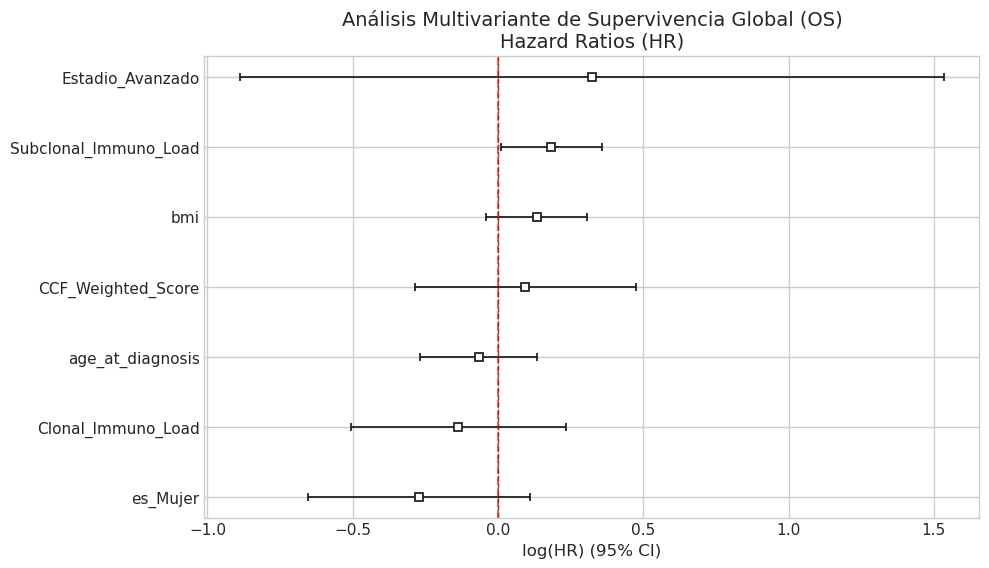

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter

# Configuración de estilo
plt.style.use('seaborn-v0_8-whitegrid')

# Rutas de archivos (ajustar según tu estructura)
path_apgi = '../data/raw/clinical_data_APGI/'
path_paca = '../data/raw/clinical_data_PACA/'

# ==============================================================================
# 1. PREPARACIÓN DE SUPERVIVENCIA GLOBAL (OS)
# ==============================================================================
print("1. Procesando Supervivencia Global (OS)...")

# Cargar donantes (contiene survival_time y vital_status)
df_donor_apgi = pd.read_csv(path_apgi + 'donor.tsv', sep='\t')
df_donor_paca = pd.read_csv(path_paca + 'donor.tsv', sep='\t')
df_clinico = pd.concat([df_donor_apgi, df_donor_paca], ignore_index=True)

df_clinico['ID_Paciente'] = 'DO' + df_clinico['donor_id'].astype(str)
df_clinico['Tiempo'] = pd.to_numeric(df_clinico['survival_time'], errors='coerce')
df_clinico['Evento'] = np.where(df_clinico['vital_status'] == 'Deceased', 1, 0)

# Rescate de tiempos con follow-up (por si survival_time es NaN)
df_fu = pd.concat([
    pd.read_csv(path_apgi + 'follow_up.tsv', sep='\t'),
    pd.read_csv(path_paca + 'follow_up.tsv', sep='\t')
], ignore_index=True)

df_fu['interval_of_followup'] = pd.to_numeric(df_fu['interval_of_followup'], errors='coerce')
ultimos_fu = df_fu.groupby('donor_id')['interval_of_followup'].max().reset_index()
ultimos_fu['ID_Paciente'] = 'DO' + ultimos_fu['donor_id'].astype(str)

df_clinico = pd.merge(df_clinico, ultimos_fu[['ID_Paciente', 'interval_of_followup']], on='ID_Paciente', how='left')
df_clinico['Tiempo'] = df_clinico['Tiempo'].fillna(df_clinico['interval_of_followup'])
df_clinico = df_clinico.dropna(subset=['Tiempo', 'Evento'])

# ==============================================================================
# 2. INTEGRACIÓN DE COVARIABLES (EDAD, SEXO, ESTADIO, BMI)
# ==============================================================================
print("2. Integrando covariables clínicas...")

# BMI y Edad ya están en df_clinico o primary_diagnosis
df_diag = pd.concat([
    pd.read_csv(path_apgi + 'primary_diagnosis.tsv', sep='\t'),
    pd.read_csv(path_paca + 'primary_diagnosis.tsv', sep='\t')
], ignore_index=True)
df_age = df_diag[['donor_id', 'age_at_diagnosis']].drop_duplicates('donor_id')

# Sexo (desde sample_registration)
df_samp = pd.concat([
    pd.read_csv(path_apgi + 'sample_registration.tsv', sep='\t'),
    pd.read_csv(path_paca + 'sample_registration.tsv', sep='\t')
], ignore_index=True)
df_sex = df_samp[['donor_id', 'gender']].drop_duplicates('donor_id')
df_sex['es_Mujer'] = np.where(df_sex['gender'].str.lower() == 'female', 1, 0)

# Estadio (desde specimen)
df_spec = pd.concat([
    pd.read_csv(path_apgi + 'specimen.tsv', sep='\t'),
    pd.read_csv(path_paca + 'specimen.tsv', sep='\t')
], ignore_index=True)
df_stage = df_spec[['donor_id', 'pathological_stage_group']].dropna().drop_duplicates('donor_id')
df_stage['Estadio_Avanzado'] = df_stage['pathological_stage_group'].apply(
    lambda x: 1 if any(s in str(x).upper() for s in ['III', 'IV']) else 0
)

# Merge de covariables
df_covs = df_clinico[['ID_Paciente', 'donor_id', 'bmi', 'Tiempo', 'Evento']]
df_covs = df_covs.merge(df_age, on='donor_id', how='left')
df_covs = df_covs.merge(df_sex[['donor_id', 'es_Mujer']], on='donor_id', how='left')
df_covs = df_covs.merge(df_stage[['donor_id', 'Estadio_Avanzado']], on='donor_id', how='left')

# Limpieza rápida e imputación
df_covs['bmi'] = df_covs['bmi'].fillna(df_covs['bmi'].median())
df_covs['age_at_diagnosis'] = df_covs['age_at_diagnosis'].fillna(df_covs['age_at_diagnosis'].median())
df_covs['Estadio_Avanzado'] = df_covs['Estadio_Avanzado'].fillna(0)
df_covs['es_Mujer'] = df_covs['es_Mujer'].fillna(0)

# ==============================================================================
# 3. UNIÓN CON MÉTRICAS DE FILOGENIA (Ya calculadas previamente)
# ==============================================================================
# Asumiendo que 'df_metrics' contiene: ID_Paciente, Clonal_Immuno_Load, Subclonal_Immuno_Load, CCF_Weighted_Score
df_cox = pd.merge(df_covs, df_metrics, on='ID_Paciente', how='inner')

# Estandarización (Z-score) para variables continuas
cols_std = ['Clonal_Immuno_Load', 'Subclonal_Immuno_Load', 'CCF_Weighted_Score', 'bmi', 'age_at_diagnosis']
for col in cols_std:
    df_cox[col] = (df_cox[col] - df_cox[col].mean()) / df_cox[col].std()

# Eliminar IDs para el fit
df_fit = df_cox.drop(columns=['ID_Paciente', 'donor_id']).astype(float)

# ==============================================================================
# 4. MODELO DE COX Y VISUALIZACIÓN
# ==============================================================================
cph_os = CoxPHFitter(penalizer=0.1) # Penalizador para estabilidad multivariante
cph_os.fit(df_fit, duration_col='Tiempo', event_col='Evento')

print("\n--- RESUMEN MODELO COX OS (GLOBAL) ---")
cph_os.print_summary()

plt.figure(figsize=(10, 6))
cph_os.plot()
plt.title("Análisis Multivariante de Supervivencia Global (OS)\nHazard Ratios (HR)", fontsize=14)
plt.axvline(0, color='red', linestyle='--', alpha=0.6)
plt.show()

/tmp/ipykernel_2941/1084183561.py:42: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.text(summary['exp(coef) upper 95%'][i] + (max_upper * 0.05), i, label,


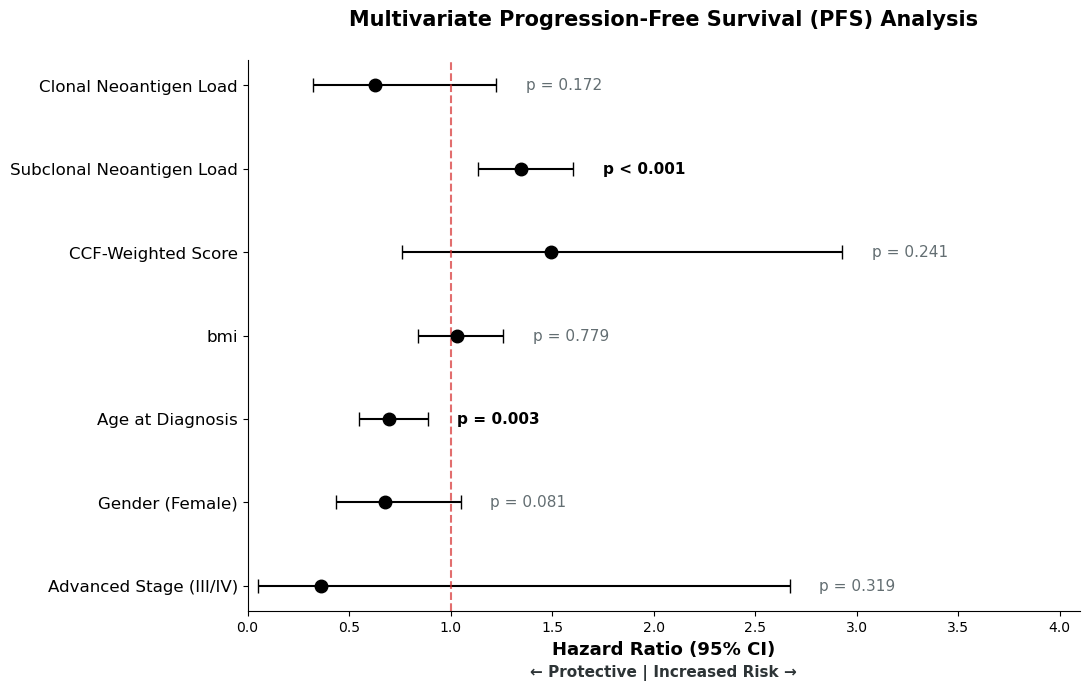

In [5]:
import matplotlib.pyplot as plt

# 1. Extract model results
summary = cph_super.summary[['exp(coef)', 'exp(coef) lower 95%', 'exp(coef) upper 95%', 'p']]

rename_map = {
   'Clonal_Immuno_Load': 'Clonal Neoantigen Load',
   'Subclonal_Immuno_Load': 'Subclonal Neoantigen Load',
   'CCF_Weighted_Score': 'CCF-Weighted Score',
   'age_at_diagnosis': 'Age at Diagnosis',
   'gender_Female': 'Gender (Female)',
   'Stage_Advanced': 'Advanced Stage (III/IV)'
}
summary.index = [rename_map.get(x, x) for x in summary.index]

plt.figure(figsize=(11, 7))
plt.style.use('default') 
ax = plt.gca()

# 2. Draw points and error bars
y_pos = range(len(summary))
plt.errorbar(summary['exp(coef)'], y_pos, 
             xerr=[summary['exp(coef)'] - summary['exp(coef) lower 95%'], 
                   summary['exp(coef) upper 95%'] - summary['exp(coef)']],
             fmt='o', color='black', ecolor='black', capsize=5, markersize=9, elinewidth=1.5)

# 3. Reference line at HR = 1 and axis setup
plt.axvline(x=1, color='#d63031', linestyle='--', alpha=0.7, linewidth=1.5)
plt.yticks(y_pos, summary.index, fontsize=12)
plt.xlabel('Hazard Ratio (95% CI)', fontsize=13, fontweight='bold')
plt.title('Multivariate Progression-Free Survival (PFS) Analysis', fontsize=15, fontweight='bold', pad=25)

# --- ENSURE TEXT STAYS WITHIN BOUNDS ---
# We calculate the maximum whisker value and add 40% padding
max_upper = summary['exp(coef) upper 95%'].max()
plt.xlim(0, max_upper * 1.4) 

# 4. Add P-values with conditional formatting
for i, p_val in enumerate(summary['p']):
    label = f"p = {p_val:.3f}" if p_val >= 0.001 else "p < 0.001"
    # Placement right after the upper confidence interval
    plt.text(summary['exp(coef) upper 95%'][i] + (max_upper * 0.05), i, label, 
             va='center', fontsize=11, 
             fontweight='bold' if p_val < 0.05 else 'normal',
             color='black' if p_val < 0.05 else '#636e72')

# Final aesthetics
plt.gca().invert_yaxis()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Add informative indicators at the bottom
plt.text(0.5, -0.12, '← Protective | Increased Risk →', 
         transform=ax.transAxes, ha='center', fontsize=11, fontweight='bold', color='#2d3436')

plt.tight_layout()

# Save for publication
plt.savefig("../results/figures/phylogeny_survival/Forest_Plot_PFS.png", dpi=300, bbox_inches='tight')

plt.show()

In [6]:
# 1. Definir el umbral de inmunogenicidad
umbral = 0.5

# 2. Filtrar para excluir 'Unknown' y quedarnos solo con Clonal/Subclonal
df_conocidos = df_plot[df_plot['clonality'].isin(['Clonal', 'Subclonal'])]

# 3. Calcular cuántos son inmunogénicos por cada grupo
conteo_inmuno = df_conocidos[df_conocidos['Immunogenicity_Probability'] >= umbral].groupby('clonality').size()

# 4. Calcular el total de conocidos para ponerlo en contexto (opcional pero útil)
total_conocidos = df_conocidos.groupby('clonality').size()

print("--- RESULTADOS DE INMUNOGENICIDAD (CLONALIDAD CONOCIDA) ---")
for grupo in ['Clonal', 'Subclonal']:
    n_inmuno = conteo_inmuno.get(grupo, 0)
    n_total = total_conocidos.get(grupo, 0)
    porcentaje = (n_inmuno / n_total) * 100 if n_total > 0 else 0
    
    print(f"**{grupo}**:")
    print(f"  - Inmunogénicos: {n_inmuno:,}")
    print(f"  - Total en este grupo: {n_total:,}")
    print(f"  - Porcentaje: {porcentaje:.2f}%")
    print("-" * 30)

# Total absoluto de candidatos viables
total_final = conteo_inmuno.sum()
print(f"TOTAL de neoantígenos candidatos (Conocidos + Inmunogénicos): {total_final:,}")

--- RESULTADOS DE INMUNOGENICIDAD (CLONALIDAD CONOCIDA) ---
**Clonal**:
  - Inmunogénicos: 115
  - Total en este grupo: 13,678
  - Porcentaje: 0.84%
------------------------------
**Subclonal**:
  - Inmunogénicos: 589
  - Total en este grupo: 49,252
  - Porcentaje: 1.20%
------------------------------
TOTAL de neoantígenos candidatos (Conocidos + Inmunogénicos): 704


In [7]:
df_plot.head()

,patient,mut_seq,Immunogenicity_Probability,CCF,clonality,Weighted_Value
0,DO33632,RLLPPWPLH,0.987290,NaN,Unknown,NaN
1,DO227652,QYKTAQEIV,0.982768,NaN,Unknown,NaN
2,DO227648,RPGAPPSAL,0.982003,NaN,Unknown,NaN
3,DO35082,EAAPGRARR,0.981567,NaN,Unknown,NaN
4,DO35350,PILFFFSSK,0.980385,NaN,Unknown,NaN


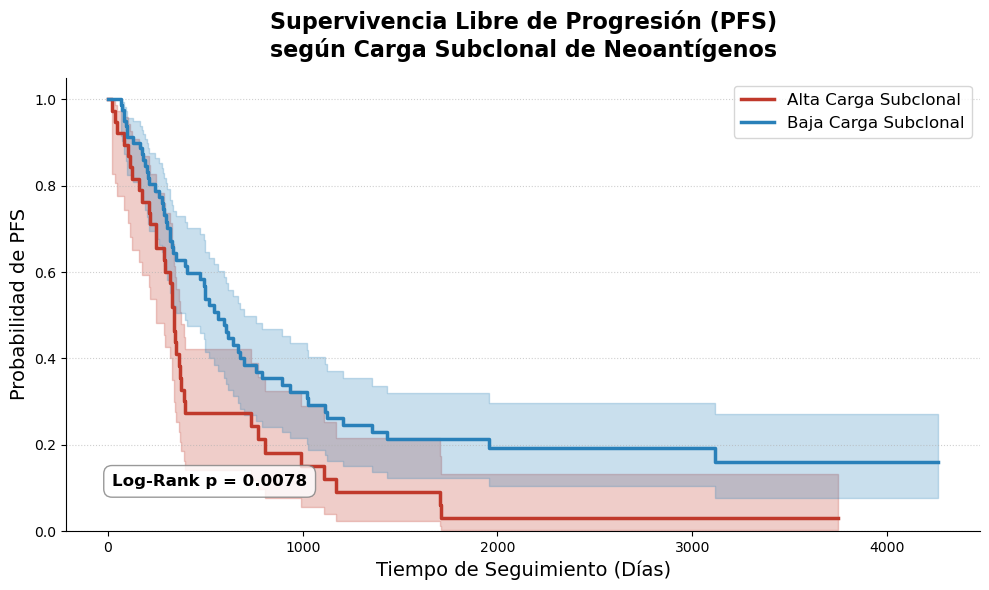

In [8]:
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Reconstruir los datos de PFS específicamente para evitar el KeyError
df_plot_pfs = pd.merge(df_pfs[['ID_Paciente', 'PFS_Time', 'PFS_Event']], df_metrics, on='ID_Paciente', how='inner')

# 2. Definir los grupos: Alta vs Baja Carga Subclonal
# Usamos la mediana para dividir a la cohorte en dos grupos
mediana_subclonal = df_plot_pfs['Subclonal_Immuno_Load'].median()

# Crear una nueva columna categórica
df_plot_pfs['Grupo_Subclonal'] = df_plot_pfs['Subclonal_Immuno_Load'].apply(
    lambda x: 'Alta Carga Subclonal' if x > mediana_subclonal else 'Baja Carga Subclonal'
)

# 3. Inicializar estimadores de Kaplan-Meier
kmf_alta = KaplanMeierFitter()
kmf_baja = KaplanMeierFitter()

# 4. Separar los datos
df_alta = df_plot_pfs[df_plot_pfs['Grupo_Subclonal'] == 'Alta Carga Subclonal']
df_baja = df_plot_pfs[df_plot_pfs['Grupo_Subclonal'] == 'Baja Carga Subclonal']

# 5. Crear la figura
plt.figure(figsize=(10, 6))

# Ajustar y graficar grupo de Alta Carga (Rojo)
kmf_alta.fit(durations=df_alta['PFS_Time'], event_observed=df_alta['PFS_Event'], label='Alta Carga Subclonal')
ax = kmf_alta.plot_survival_function(color='#c0392b', linewidth=2.5)

# Ajustar y graficar grupo de Baja Carga (Azul)
kmf_baja.fit(durations=df_baja['PFS_Time'], event_observed=df_baja['PFS_Event'], label='Baja Carga Subclonal')
kmf_baja.plot_survival_function(ax=ax, color='#2980b9', linewidth=2.5)

# 6. Calcular el p-valor usando Log-Rank Test
resultados_lr = logrank_test(
    durations_A=df_alta['PFS_Time'], 
    durations_B=df_baja['PFS_Time'], 
    event_observed_A=df_alta['PFS_Event'], 
    event_observed_B=df_baja['PFS_Event']
)
p_valor = resultados_lr.p_value

# 7. Personalizar el gráfico
plt.title('Supervivencia Libre de Progresión (PFS)\nsegún Carga Subclonal de Neoantígenos', 
          fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Tiempo de Seguimiento (Días)', fontsize=14)
plt.ylabel('Probabilidad de PFS', fontsize=14)
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Añadir el p-valor al gráfico
texto_p = f'Log-Rank p = {p_valor:.4f}' if p_valor >= 0.001 else 'Log-Rank p < 0.001'
plt.text(0.05, 0.1, texto_p, transform=ax.transAxes, fontsize=12, fontweight='bold',
         bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray', boxstyle='round,pad=0.5'))

# Ajustar leyenda y bordes
plt.legend(fontsize=12, loc='upper right')
sns.despine()
plt.tight_layout()

plt.savefig('../results/figures/phylogeny_survival/Kaplan_Meier_PFS_Subclonal.png', dpi=300, bbox_inches='tight')

plt.show()

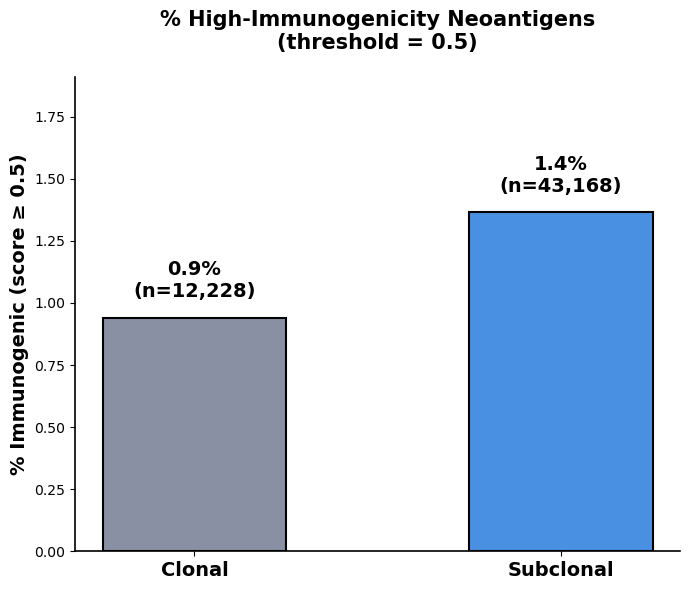

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================
# 1. PREPARAR DATOS (Usando los DFs de tu notebook)
# ==============================================================
# Asumimos que df_phylo y df_preds ya están cargados en las celdas superiores.
# Si en tu notebook la columna se llama diferente, asegúrate de renombrarla:
if 'Peptide' in df_preds.columns:
    df_preds = df_preds.rename(columns={'Peptide': 'mut_seq'})

df_plot = pd.merge(
    df_preds[['patient', 'mut_seq', 'Immunogenicity_Probability']],
    df_final[['patient', 'mut_seq', 'CCF', 'clonality']].drop_duplicates(subset=['patient','mut_seq']),
    on=['patient', 'mut_seq'], 
    how='inner'
)

df_plot['clonality'] = df_plot['clonality'].astype(str).str.capitalize().str.strip()
df_plot = df_plot[df_plot['clonality'].isin(['Clonal', 'Subclonal'])].copy()
df_plot = df_plot.dropna(subset=['Immunogenicity_Probability', 'CCF'])

# ==============================================================
# 2. PARÁMETROS DEL GRÁFICO
# ==============================================================
colors  = {'Clonal': '#8A90A4', 'Subclonal': '#4A90E2'}
THRESH  = 0.5   # Umbral inmunogenicidad alta

# ==============================================================
# 3. CREAR FIGURA B (Barplot)
# ==============================================================
fig_b, ax_b = plt.subplots(figsize=(7, 6))

# Forzar explícitamente el fondo blanco
fig_b.patch.set_facecolor('white')
ax_b.set_facecolor('white')

# Calcular porcentajes
df_plot['is_immunogenic'] = df_plot['Immunogenicity_Probability'] >= THRESH
pct = df_plot.groupby('clonality')['is_immunogenic'].mean() * 100
n_per_group = df_plot.groupby('clonality').size()

bars = ax_b.bar(pct.index, pct.values,
                color=[colors[x] for x in pct.index],
                edgecolor='black', linewidth=1.5, width=0.5)

# Calculamos un espacio dinámico proporcional para las etiquetas
espacio_texto = max(pct.values) * 0.05 

for bar, val, n in zip(bars, pct.values, [n_per_group.get('Clonal',0), n_per_group.get('Subclonal',0)]):
    ax_b.text(bar.get_x() + bar.get_width()/2, bar.get_height() + espacio_texto,
              f"{val:.1f}%\n(n={n:,})", ha='center', va='bottom',
              fontsize=14, fontweight='bold', color='black')

# Textos y títulos
ax_b.set_ylabel(f"% Immunogenic (score ≥ {THRESH})", fontsize=14, fontweight='bold', color='black')
ax_b.set_xticks(range(len(pct.index)))
ax_b.set_xticklabels(pct.index, fontsize=14, fontweight='bold', color='black')
ax_b.set_title(f"% High-Immunogenicity Neoantigens\n(threshold = {THRESH})",
               fontsize=15, fontweight='bold', pad=20, color='black')

# -------------------------------------------------------------
# CONTROL EXPLICITO DE LOS EJES (Líneas Negras)
# -------------------------------------------------------------
ax_b.grid(False) # Quitar cuadrícula interna
ax_b.spines['bottom'].set_color('black')
ax_b.spines['bottom'].set_linewidth(1.2)
ax_b.spines['left'].set_color('black')
ax_b.spines['left'].set_linewidth(1.2)
ax_b.tick_params(axis='x', colors='black')
ax_b.tick_params(axis='y', colors='black')

# Quitar ejes superior y derecho
ax_b.spines['top'].set_visible(False)
ax_b.spines['right'].set_visible(False)

# Ajustar margen superior para que quepa el texto
ax_b.set_ylim(0, max(pct.values) * 1.4)

plt.tight_layout()

# Opcional: Guardar la imagen si corres el notebook localmente
# fig_b.savefig("Figura_B_Immunogenicity.png", dpi=300, bbox_inches='tight', facecolor='white')

plt.show()